# BTS Flight Delay EDA


In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [18]:
columns = [
    'Reporting_Airline', 'Origin', 'Dest', 'FlightDate',
    'CRSDepTime', 'CRSArrTime', 'Distance', 'CRSElapsedTime',
    'Flight_Number_Reporting_Airline', 'Cancelled', 'Diverted', 'ArrDel15'
]
str_cols = [
    'Reporting_Airline', 'Origin', 'Dest',
    'Flight_Number_Reporting_Airline', 'CRSDepTime', 'CRSArrTime'
]

raw = pd.read_csv(
    '../data/bronze/bts/2024/01/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_1.csv',
    usecols=columns,
    dtype={col: str for col in str_cols},
    parse_dates=['FlightDate'],
    keep_default_na=False,
    na_values=[''],
)
print(f"Shape: {raw.shape}")
raw.head()


Shape: (547271, 12)


,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,Dest,CRSDepTime,CRSArrTime,ArrDel15,Cancelled,Diverted,CRSElapsedTime,Distance
0,2024-01-08,9E,4801,LGA,OMA,0856,1135,0.0,0.0,0.0,219.0,1148.0
1,2024-01-09,9E,4801,LGA,OMA,0856,1135,0.0,0.0,0.0,219.0,1148.0
2,2024-01-10,9E,4801,LGA,OMA,0856,1135,0.0,0.0,0.0,219.0,1148.0
3,2024-01-11,9E,4801,LGA,OMA,0856,1135,1.0,0.0,0.0,219.0,1148.0
4,2024-01-12,9E,4801,LGA,OMA,0856,1135,0.0,0.0,0.0,219.0,1148.0


In [ ]:
raw.dtypes.to_frame('dtype')

,dtype
FlightDate,datetime64[ns]
Reporting_Airline,object
Flight_Number_Reporting_Airline,object
Origin,object
Dest,object
CRSDepTime,object
CRSArrTime,object
ArrDel15,float64
Cancelled,float64
Diverted,float64


## Data Quality


In [31]:
df = raw.copy()
df['DepHour'] = (df['CRSDepTime'].astype(int) // 100) % 24
df['DayOfWeek'] = df['FlightDate'].dt.dayofweek + 1

# Missing values
missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2)
})
display(missing[missing['missing'] > 0])



,missing,missing_pct
ArrDel15,21901,4.0


In [32]:
# Integrity checks
key = ['FlightDate', 'Reporting_Airline', 'Flight_Number_Reporting_Airline', 'Origin', 'Dest', 'CRSDepTime']
display(pd.Series({
    'duplicate_rows': df.duplicated().sum(),
    'repeated_keys': df[key].dropna().duplicated().sum(),
    'incomplete_keys': df[key].isna().any(axis=1).sum(),
    'invalid_distance_or_duration': ((df['Distance'] <= 0) | (df['CRSElapsedTime'] <= 0)).sum()
}))


duplicate_rows                  0
repeated_keys                   0
incomplete_keys                 0
invalid_distance_or_duration    0
dtype: int64

In [33]:
# Text and identifier ranges use alphabetical order.
display(df.apply(lambda column: column.dropna().agg(['min', 'max'])).T)


,min,max
FlightDate,2024-01-01 00:00:00,2024-01-31 00:00:00
Reporting_Airline,9E,YX
Flight_Number_Reporting_Airline,1,999
Origin,ABE,YUM
Dest,ABE,YUM
CRSDepTime,0006,2359
CRSArrTime,0001,2359
ArrDel15,0.0,1.0
Cancelled,0.0,1.0
Diverted,0.0,1.0


## Analysing ArrDel15


In [22]:
# Filter to non-cancelled, non-diverted flights with a valid delay label
normal = df['Cancelled'].eq(0) & df['Diverted'].eq(0) & df['ArrDel15'].isin([0, 1])
flights = df.loc[normal].copy()

display(pd.Series({
    'raw_flights': len(df),
    'cancelled': df['Cancelled'].eq(1).sum(),
    'diverted': df['Diverted'].eq(1).sum(),
    'missing_target': df['ArrDel15'].isna().sum(),
    'valid_flights': len(flights)
}).to_frame('count'))

pd.crosstab(df['Cancelled'], df['ArrDel15'].isna(), rownames=['Cancelled'], colnames=['Target Missing'])


,count
raw_flights,547271
cancelled,20389
diverted,1512
missing_target,21901
valid_flights,525370


Target Missing,False,True
Cancelled,,
0.0,525370,1512
1.0,0,20389


## ArrDel15 Distribution


,count,pct
ArrDel15,,
0.0,398960,75.94
1.0,126410,24.06


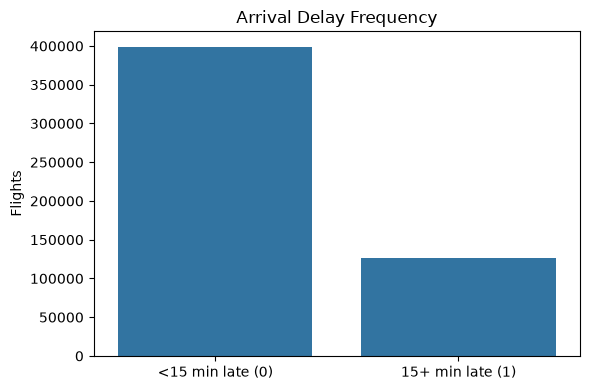

In [23]:
balance = pd.DataFrame({
    'count': flights['ArrDel15'].value_counts().sort_index(),
    'pct': (flights['ArrDel15'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(balance)

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=flights, x='ArrDel15')
plt.xticks([0, 1], ['<15 min late (0)', '15+ min late (1)'])
plt.title('Arrival Delay Frequency')
plt.xlabel('')
plt.ylabel('Flights')
plt.tight_layout()
plt.show()


## Daily Delay Trends


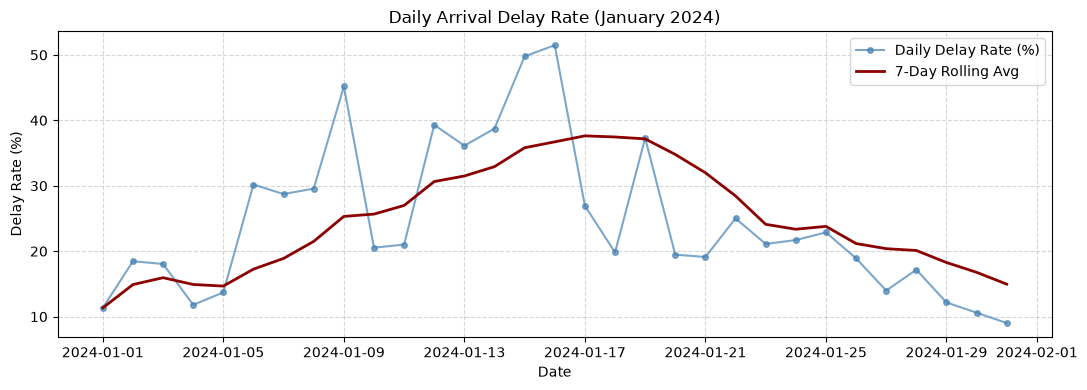

In [24]:
daily = flights.groupby('FlightDate')['ArrDel15'].mean() * 100
rolling_7d = daily.rolling(7, min_periods=1).mean()

plt.figure(figsize=(11, 4))
plt.plot(daily.index, daily.values, marker='o', markersize=4, label='Daily Delay Rate (%)', color='steelblue', alpha=0.7)
plt.plot(daily.index, rolling_7d.values, linewidth=2, label='7-Day Rolling Avg', color='darkred')
plt.title('Daily Arrival Delay Rate (January 2024)')
plt.xlabel('Date')
plt.ylabel('Delay Rate (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


## Distance & Scheduled Duration


,count,mean,std,min,25%,50%,75%,max
Distance,525370.0,833.2,590.7,31.0,402.0,692.0,1069.0,5095.0
CRSElapsedTime,525370.0,148.6,72.9,26.0,95.0,133.0,180.0,690.0


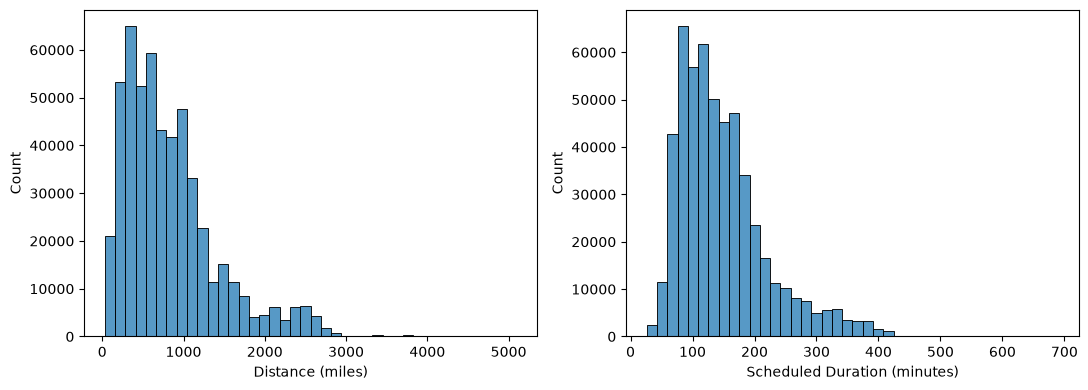

In [25]:
display(flights[['Distance', 'CRSElapsedTime']].describe().round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=flights, x='Distance', bins=40, ax=axes[0])
sns.histplot(data=flights, x='CRSElapsedTime', bins=40, ax=axes[1])
axes[0].set_xlabel('Distance (miles)')
axes[1].set_xlabel('Scheduled Duration (minutes)')
plt.tight_layout()
plt.show()


## Delays by Airline & Airport


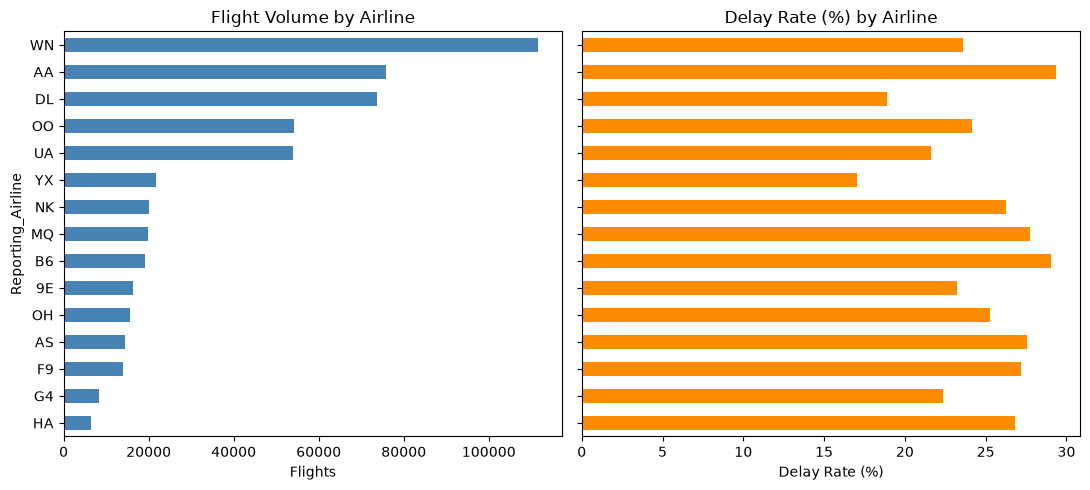

In [26]:
airlines = flights.groupby('Reporting_Airline').agg(
    flights=('ArrDel15', 'size'),
    delayed=('ArrDel15', 'sum'),
    delay_rate=('ArrDel15', 'mean'),
    mean_distance=('Distance', 'mean')
)
airlines['delay_pct'] = (airlines['delay_rate'] * 100).round(2)

ordered = airlines.sort_values('flights')
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
ordered['flights'].plot.barh(ax=axes[0], color='steelblue')
ordered['delay_pct'].plot.barh(ax=axes[1], color='darkorange')
axes[0].set_xlabel('Flights')
axes[1].set_xlabel('Delay Rate (%)')
axes[0].set_title('Flight Volume by Airline')
axes[1].set_title('Delay Rate (%) by Airline')
plt.tight_layout()
plt.show()


In [27]:
airports = flights.groupby('Origin').agg(flights=('ArrDel15', 'size'), delay_rate=('ArrDel15', 'mean'))
airports['delay_pct'] = (airports['delay_rate'] * 100).round(2)

display(airports.sort_values('flights', ascending=False).head(10))
print(f"Origin airports: {flights['Origin'].nunique()} | Destination airports: {flights['Dest'].nunique()}")


,flights,delay_rate,delay_pct
Origin,,,
ATL,25963,0.209722,20.97
DFW,22808,0.303885,30.39
DEN,22309,0.259985,26.00
ORD,18816,0.322970,32.30
CLT,16037,0.271871,27.19
PHX,15029,0.207332,20.73
LAX,14711,0.192713,19.27
LAS,14539,0.215902,21.59
MCO,13844,0.267408,26.74


Origin airports: 334 | Destination airports: 334


## Departure Timing


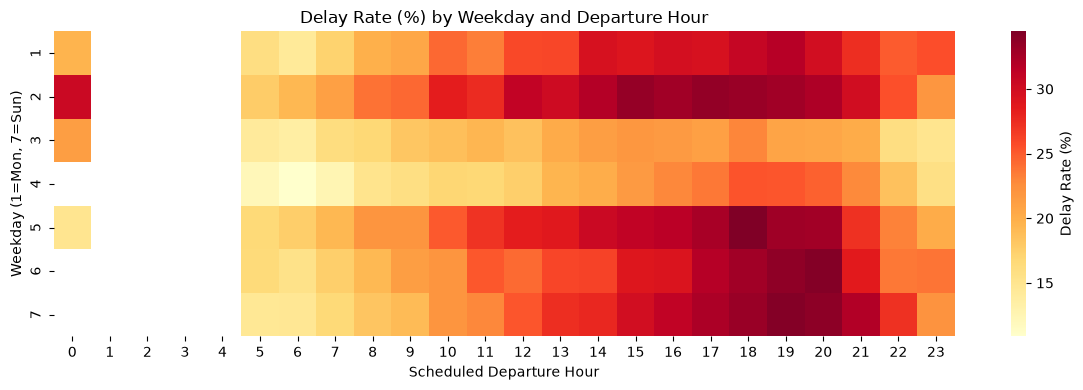

In [28]:
delay_table = flights.pivot_table(index='DayOfWeek', columns='DepHour', values='ArrDel15', aggfunc='mean') * 100
count_table = flights.pivot_table(index='DayOfWeek', columns='DepHour', values='ArrDel15', aggfunc='count')

plt.figure(figsize=(12, 4))
sns.heatmap(delay_table, mask=count_table.lt(100), cmap='YlOrRd', cbar_kws={'label': 'Delay Rate (%)'})
plt.title('Delay Rate (%) by Weekday and Departure Hour')
plt.xlabel('Scheduled Departure Hour')
plt.ylabel('Weekday (1=Mon, 7=Sun)')
plt.tight_layout()
plt.show()


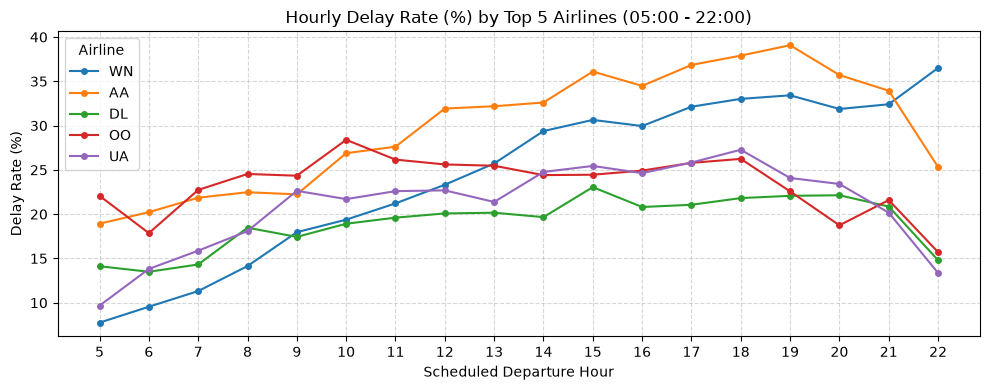

In [29]:
top5 = flights['Reporting_Airline'].value_counts().head(5).index
hourly_airline = flights[flights['Reporting_Airline'].isin(top5)].pivot_table(
    index='DepHour', columns='Reporting_Airline', values='ArrDel15', aggfunc='mean'
) * 100

plt.figure(figsize=(10, 4))
for airline in top5:
    series = hourly_airline.loc[5:22, airline]
    plt.plot(series.index, series.values, marker='o', markersize=4, label=airline)
plt.title('Hourly Delay Rate (%) by Top 5 Airlines (05:00 - 22:00)')
plt.xlabel('Scheduled Departure Hour')
plt.ylabel('Delay Rate (%)')
plt.xticks(range(5, 23))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Airline')
plt.tight_layout()
plt.show()


## Feature Correlations


,ArrDel15
DepHour,0.0984
Distance,0.0078
CRSElapsedTime,0.0067
DayOfWeek,0.0024


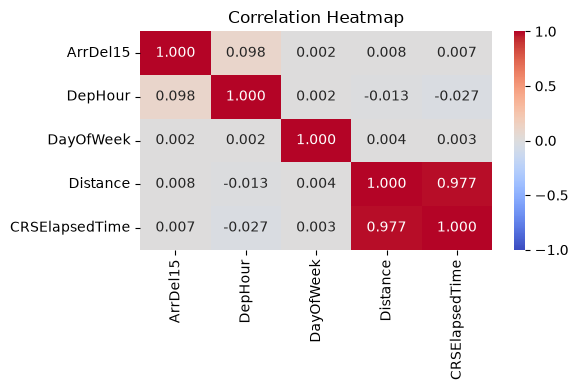

In [30]:
num_cols = ['ArrDel15', 'DepHour', 'DayOfWeek', 'Distance', 'CRSElapsedTime']
corr = flights[num_cols].corr()
display(corr[['ArrDel15']].drop(index='ArrDel15').sort_values('ArrDel15', ascending=False).round(4))

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()
